# Auction-Based Allocation 

In [1]:
import sys, os
sys.path.append(os.path.abspath("C:/Users/bomma/Desktop/DESKTOP_MAIN_DISP/MATHS_PROJECT_SEM5/A_project_re/project_COMPLETE_all_5_days/project/src"))

from environment import Environment
from robots import RobotFleet
from tasks import TaskManager
from battery import BatteryModel
from auction import run_auction, DEFAULT_WEIGHTS

DATASET_ROOT = "C:/Users/bomma/Desktop/DESKTOP_MAIN_DISP/MATHS_PROJECT_SEM5/A_project_re/project_COMPLETE_all_5_days/project/data/dataset"
env = Environment(DATASET_ROOT)
fleet = RobotFleet(DATASET_ROOT)
batt = BatteryModel(fleet, DATASET_ROOT)
tm = TaskManager(DATASET_ROOT)

print("Bid weights (normalized, sum = %.2f):" % sum(DEFAULT_WEIGHTS.values()))
for k, v in DEFAULT_WEIGHTS.items():
    print(f"  {k:20s} {v:.2f}")


Bid weights (normalized, sum = 1.00):
  priority             0.20
  distance_cost        0.15
  path_cost            0.10
  predicted_energy     0.15
  soc                  0.12
  dod                  0.05
  soh                  0.05
  risk                 0.08
  deadline             0.05
  workload_fairness    0.05


## Run the auction

In [2]:
assignment = run_auction(list(fleet.robots.values()), tm.active_tasks(), env, batt)
print(f"Auction assigned {len(assignment)} / {len(fleet.robots)} robots\n")
for rid, bid in sorted(assignment.items(), key=lambda kv: -kv[1].score):
    print(bid.explanation())


Auction assigned 12 / 12 robots

UAV02 -> T03 | score=0.913 | priority=1.000, distance_cost=0.876, path_cost=0.893, predicted_energy=0.779, soc=0.973, dod=0.973, soh=0.995, risk=0.750, deadline=1.000, workload_fairness=1.000, predicted_energy_wh=88.477, distance_raw=14.828
USV01 -> T13 | score=0.846 | priority=1.000, distance_cost=0.870, path_cost=0.861, predicted_energy=0.880, soc=0.794, dod=0.794, soh=0.855, risk=0.250, deadline=1.000, workload_fairness=1.000, predicted_energy_wh=47.953, distance_raw=15.657
USV02 -> T14 | score=0.830 | priority=0.800, distance_cost=0.836, path_cost=0.842, predicted_energy=0.822, soc=0.899, dod=0.899, soh=0.892, risk=0.500, deadline=1.000, workload_fairness=1.000, predicted_energy_wh=71.223, distance_raw=19.657
UGV01 -> T09 | score=0.800 | priority=0.600, distance_cost=0.863, path_cost=0.881, predicted_energy=0.813, soc=0.793, dod=0.793, soh=0.916, risk=0.750, deadline=1.000, workload_fairness=1.000, predicted_energy_wh=74.636, distance_raw=16.485
UAV

### Explaining individual bids 

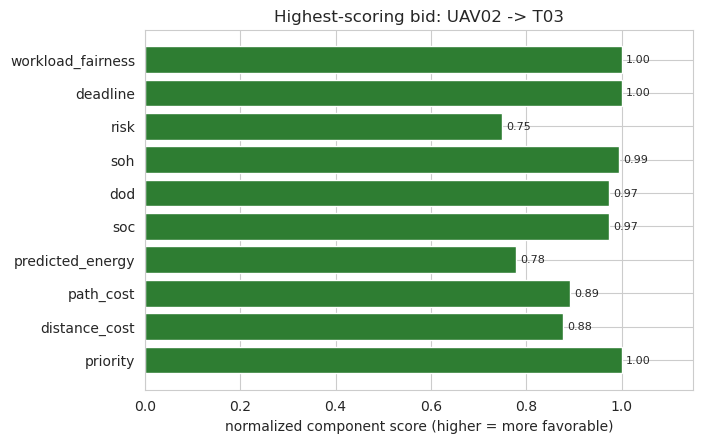

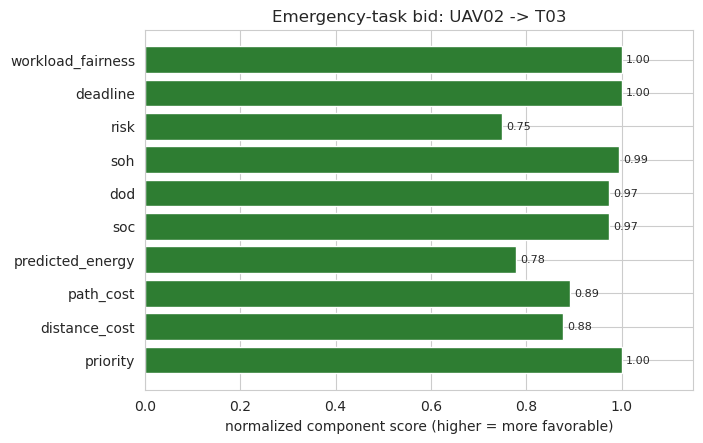

In [3]:
import matplotlib.pyplot as plt
from visualization import plot_bid_breakdown

# Show the breakdown for the highest-scoring bid and, separately, for an
# emergency-task bid if one exists in this assignment.
best_rid, best_bid = max(assignment.items(), key=lambda kv: kv[1].score)
plot_bid_breakdown(best_bid, title=f"Highest-scoring bid: {best_bid.robot_id} -> {best_bid.task_id}")
plt.savefig("../results/day2_bid_breakdown_top.png", dpi=150, bbox_inches="tight")
plt.show()

emergency_bids = [b for b in assignment.values() if b.task_id in
                   {t.task_id for t in tm.active_tasks() if t.emergency}]
if emergency_bids:
    plot_bid_breakdown(emergency_bids[0], title=f"Emergency-task bid: {emergency_bids[0].robot_id} -> {emergency_bids[0].task_id}")
    plt.savefig("../results/day2_bid_breakdown_emergency.png", dpi=150, bbox_inches="tight")
    plt.show()


## Verify: emergency tasks get priority treatment

In [4]:
emergency_ids = {t.task_id for t in tm.active_tasks() if t.emergency}
won_emergency = [b for b in assignment.values() if b.task_id in emergency_ids]
print(f"Emergency tasks won: {len(won_emergency)} / {len(emergency_ids)} total emergencies")
assert len(won_emergency) == len(emergency_ids), "All emergencies should be won given feasible robots exist"
print("OK: every emergency task received a robot in this run.")


Emergency tasks won: 3 / 3 total emergencies
OK: every emergency task received a robot in this run.


Best bid type: <class 'auction.Bid'>
Best bid details: {'robot_id': 'UAV02', 'task_id': 'T03', 'score': 0.9127360723224235, 'components': {'priority': 1.0, 'distance_cost': 0.8764297739604484, 'path_cost': 0.8929058040990553, 'predicted_energy': 0.778806838789671, 'soc': 0.973, 'dod': 0.973, 'soh': 0.995, 'risk': 0.75, 'deadline': 1.0, 'workload_fairness': 1.0, 'predicted_energy_wh': 88.4772644841316, 'distance_raw': 14.82842712474619}, 'path': PathResult(path=[(88, 90), (86, 90), (84, 90), (82, 90), (80, 90), (78, 90), (76, 90), (74, 92)], path_length=14.82842712474619, travel_cost=19.27695526217005, found=True)}

Only the winning bid is available.


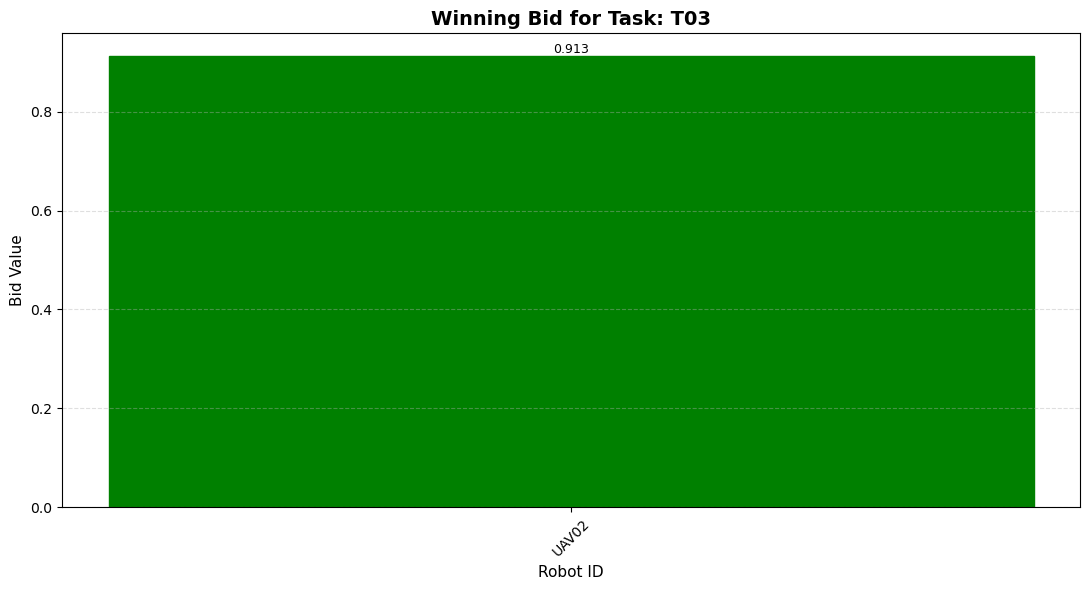


Auction Result
----------------------------------------
Winning robot: UAV02
Winning bid: 0.913
Number of robots compared: 1
Figure saved to: ../results/day2_bid_comparison.png


In [6]:
import matplotlib.pyplot as plt
from collections.abc import Mapping

# ---------------------------------------------------------
# 1. Inspect the best bid object
# ---------------------------------------------------------

print("Best bid type:", type(best_bid))
print("Best bid details:", vars(best_bid))


# ---------------------------------------------------------
# 2. Find all available bids
# ---------------------------------------------------------
# The code checks common variable names that may already
# exist in your auction notebook.

possible_bid_collections = [
    "all_bids",
    "bids",
    "robot_bids",
    "candidate_bids",
    "feasible_bids",
    "bid_history"
]

bid_collection = None
bid_collection_name = None

for variable_name in possible_bid_collections:
    if variable_name in globals():
        candidate = globals()[variable_name]

        if isinstance(candidate, Mapping) and len(candidate) > 0:
            bid_collection = candidate
            bid_collection_name = variable_name
            break


# ---------------------------------------------------------
# 3. If no bid dictionary exists, create one from best_bid
# ---------------------------------------------------------

if bid_collection is None:
    print("\nWarning: No dictionary containing all robot bids was found.")
    print("Only the winning bid is available.")

    # Read robot ID from the Bid object
    winning_robot = getattr(
        best_bid,
        "robot_id",
        getattr(best_bid, "robot", "Unknown Robot")
    )

    # Read task ID from the Bid object
    winning_task = getattr(
        best_bid,
        "task_id",
        getattr(best_bid, "task", "Unknown Task")
    )

    # Read the bid value from the Bid object
    winning_bid = None

    possible_value_names = [
        "bid_value",
        "value",
        "score",
        "utility",
        "total_score",
        "cost"
    ]

    for value_name in possible_value_names:
        if hasattr(best_bid, value_name):
            winning_bid = getattr(best_bid, value_name)
            break

    if winning_bid is None:
        raise AttributeError(
            "Could not find the bid value. "
            "Check vars(best_bid) and update possible_value_names."
        )

    robot_ids = [str(winning_robot)]
    bid_values = [float(winning_bid)]

    chart_title = f"Winning Bid for Task: {winning_task}"

else:
    print(f"\nUsing bid collection: {bid_collection_name}")

    robot_ids = []
    bid_values = []

    for robot_id, bid_data in bid_collection.items():

        # Case 1: dictionary value is already a number
        if isinstance(bid_data, (int, float)):
            bid_value = float(bid_data)

        # Case 2: dictionary value is a Bid object
        else:
            bid_value = None

            possible_value_names = [
                "bid_value",
                "value",
                "score",
                "utility",
                "total_score",
                "cost"
            ]

            for value_name in possible_value_names:
                if hasattr(bid_data, value_name):
                    bid_value = getattr(bid_data, value_name)
                    break

            if bid_value is None and isinstance(bid_data, Mapping):
                for value_name in possible_value_names:
                    if value_name in bid_data:
                        bid_value = bid_data[value_name]
                        break

        if bid_value is not None:
            robot_ids.append(str(robot_id))
            bid_values.append(float(bid_value))

    if len(bid_values) == 0:
        raise ValueError(
            "The bid collection was found, but no numeric bid values "
            "could be extracted."
        )

    chart_title = "Bid Comparison Among Feasible Robots"


# ---------------------------------------------------------
# 4. Identify the winning robot
# ---------------------------------------------------------

winning_index = bid_values.index(max(bid_values))
winning_robot = robot_ids[winning_index]
winning_bid = bid_values[winning_index]


# ---------------------------------------------------------
# 5. Plot the bid comparison chart
# ---------------------------------------------------------

plt.figure(figsize=(11, 6))

bars = plt.bar(
    robot_ids,
    bid_values,
    color="steelblue",
    edgecolor="black"
)

# Highlight the winning robot
bars[winning_index].set_color("green")

# Add bid values above every bar
for index, bar in enumerate(bars):
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{bid_values[index]:.3f}",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.title(chart_title, fontsize=14, fontweight="bold")
plt.xlabel("Robot ID", fontsize=11)
plt.ylabel("Bid Value", fontsize=11)

plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()

# Save the figure
plt.savefig(
    "../results/day2_bid_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ---------------------------------------------------------
# 6. Print the auction result
# ---------------------------------------------------------

print("\nAuction Result")
print("-" * 40)
print("Winning robot:", winning_robot)
print("Winning bid:", round(winning_bid, 3))
print("Number of robots compared:", len(robot_ids))
print("Figure saved to: ../results/day2_bid_comparison.png")